# mini-vLLM, Part 3: Continuous Batching

**What we will build and measure**

[Stage 3](https://github.com/chizkidd/minivllm/blob/main/02_static_batching.ipynb) ended with a diagnosis:
>_static batching makes every request in a batch wait for the longest one. Finished requests keep their slot and keep being computed, short requests sit finished until the batch returns, and the KV cache is reserved as one rectangle sized for the worst case._

**Stage 4, continuous batching** removes the waiting, then measures what that buys and what it costs.

1. **Give every sequence its own slot and its own length:** a pool of KV slots, and a scheduler that frees a slot the moment its request finishes and prefills a waiting request into it, while the others keep decoding. Prove it still produces exactly the same tokens as running each request alone.
2. **Measure the recovery:** at the same concurrency and the same requests, how much of the goodput and latency that Stage 3 lost does continuous batching win back?
3. **Measure it under load:** requests arrive over time (a Poisson process), and static and continuous batching see the same arrivals. Where does each policy stop keeping up?
4. **Measure the new cost:** every new request needs a prefill, and a prefill interrupts the decode steps of everyone already running.
5. **Measure what is left:** each slot still reserves cache for the worst case, which is exactly what Stage 5 (paged KV cache) removes.

**How to use this notebook.** Same shape as Parts 1 and 2: *Goal, Concept, Code, Result, Takeaway*, with a prediction before every benchmark. The takeaways are written as "how to read the result" because the numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 |
| --- | --- | --- | --- |
| 1 | Setup | Reproducible environment | seconds |
| 2 | The code | A slot-based KV pool, the continuous scheduler, a load generator | seconds |
| 3 | Load model and correctness gates | Continuous batching reproduces one-at-a-time results | about 1 min |
| 4 | A. Closed batch | What continuous batching wins back at fixed concurrency | about 4 min |
| 5 | B. Open-loop load | Latency and throughput as the offered load rises | about 7 min |
| 6 | C. Prefill interference | What a new request costs the requests already running | about 1 min |
| 7 | D. KV slot reservation | What is still wasted | seconds (reuses section 4 runs) |
| 8 | Save results | JSON and figure inventory | seconds |
| 9 | Publish (optional) | Push results (and code, if newest) to GitHub | seconds |
| 10 | Summary | Findings and what comes next | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a run of about 5 minutes instead of about 15.

**Self-contained.** Like Parts 1 and 2, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. Files that did not change since Part 2 are repeated verbatim. `minivllm/kv_cache.py` gained `SlotCache`, `minivllm/scheduler.py` gained `run_continuous` and `run_static_online`, and `bench/workload.py`, `bench/metrics.py` and `bench/plots.py` gained the load generator, the online metrics and a few plot helpers.

---
## 1. Setup

**Goal:** one imports cell, one environment record.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `SEED` fixes the synthetic requests, so every policy and every slot count sees exactly the same ones.
- `QUICK = True` shrinks the sweeps (fewer requests, slot counts and load levels) for a fast pass.
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: fewer requests, slot counts and load levels (about 5 minutes instead of about 15)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


---
## 2. The code

Three files changed in an important way. Read them in this order: the slot cache, the scheduler, then the benchmark helpers. The files that did not change follow at the end of this section.

### 2.1 A cache with one length per sequence (`minivllm/kv_cache.py`)

**Concept.** Stage 3's `KVCache` has **one** `length` for the whole batch, so every sequence must advance together: nobody can leave and nobody can join. `SlotCache` is a pool of `slots` slots, each a contiguous rectangle that can hold `max_len` tokens, and every slot has its **own** length (`lens`, plain Python ints, so reading them never waits for the GPU).

```
K, V tensors, each: [n_layers, slots, n_kv_heads, max_len, head_dim]

slot 0:  |<- 37 tokens ->|<------ free ------>|     one sequence, mid-generation
slot 1:  |<-------------- free -------------->|     a free slot
slot 2:  |<---- 112 tokens ----->|<-- free -->|
```

`model.forward` only needs `length`, `update` and `advance` from its cache, so two small views plug the pool into it unchanged:

- **`prefill_view(slot)`:** one new prompt, batch 1, **no padding**, written into one free slot.
- **`decode_view()`:** one token for **every** slot, each written at that slot's own column. A free slot decodes a dummy token that is masked out and overwritten later, which keeps the batch shape fixed (and costs almost nothing, as Stage 3 showed: a decode step is launch-bound, not bound by the number of rows).

Attention for one decode step uses a boolean mask `[slots, 1, 1, L]` that is `True` only up to each slot's own position. That mask is also what hides the **stale** keys a slot still holds from its previous occupant.

Each slot is still a worst-case rectangle, so memory is reserved for `max_len` tokens whether the request needs them or not. Section 7 measures that waste, and Stage 5 removes it.

### 2.2 Static batching under arrivals, and continuous batching (`minivllm/scheduler.py`)

**Concept.** In Stage 3 every request arrived at `t = 0`. Now each request has an `arrival_s`, and both policies run on a **virtual clock**: it advances by the *measured* GPU time of each step and jumps over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

- **`run_static_online`:** whenever the GPU is free it takes the requests that have already arrived, up to the batch size (it does not wait for a full batch), and runs them as one static wave exactly as Stage 3 did. If nothing is waiting it idles until the next arrival.
- **`run_continuous`:** each iteration (1) lets arrivals join a FIFO queue, (2) fills every free slot from the queue with a prefill (at most `max_prefills` of them per iteration), (3) runs one decode step for all slots, each at its own position, and (4) releases a request the moment it has produced its `max_new` tokens, freeing its slot for the next iteration.

So nothing waits for a stranger's long answer, and no slot idles while someone is queued. The price is that a prefill runs *between* decode steps, so it delays the tokens of every request already running. Section 6 measures that.

Both return the same kind of record per request: `arrival_s`, `admit_s` (when its prefill or batch started), `first_token_s`, `finish_s` (its own last token) and `release_s` (when the caller got the answer). With static batching `release_s` is the end of the batch. With continuous batching it equals `finish_s`.

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0), "prefill only from an empty cache"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


### 2.3 Unchanged from Part 2

`minivllm/model.py` (forward with optional `positions` and `attn_mask`), `minivllm/batching.py` (`left_pad`, `Layout`, still used by the static baseline), `minivllm/engine.py` (`generate_cached`, our one-at-a-time reference) and `minivllm/utils.py`.

In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/kv_cache.py
import torch

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running

Writing minivllm/kv_cache.py


In [5]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static) or slot count (continuous)
    max_len: int = 0       # tokens each slot can hold (continuous)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)

Writing minivllm/scheduler.py


In [6]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [7]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


### 2.4 Benchmark helpers (`bench/`)

| Module | New in this part |
| --- | --- |
| `bench/workload.py` | `poisson_arrivals` and `with_arrivals`: the same requests with Poisson arrival times, so every policy sees the same trace |
| `bench/metrics.py` | `summarize_online` (goodput, latency, time to first token, slot occupancy, KV slot use, the gap a running request sees between tokens) and `sweep_load` (both policies at several arrival rates) |
| `bench/plots.py` | `line_groups` and `line_groups_stacked` (one line per policy), `step_timeline` (decode steps and prefills over time) |
| `bench/publish.py` | `publish`: copy results (and code, if newest) into a clone of the repo, commit and push |

**Metrics to keep apart.** 
* <u>*Latency*</u> is what the caller sees, `release_s - arrival_s`.
* <u>*Time to first token*</u> (TTFT) is `first_token_s - arrival_s`.
* <u>*Goodput*</u> counts only the tokens each request asked for.
* <u>*Offered load*</u> is the arrival rate.
* <u>*Throughput*</u> is what the server actually completed per second, and it can never exceed the offered load for long.

In [8]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [9]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous runs add: 
      slot_occupancy:        mean active slots / slots
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs.
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
    }
    if run.steps:
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len
        out["kv_slot_util"] = mean([s["kv_tokens"] for s in run.steps]) / (run.slots * run.max_len)
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows

Writing bench/metrics.py


In [10]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [11]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None):
    """series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [12]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [13]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 3. Load the model and prove continuous batching is correct

**Goal:** load `Qwen/Qwen2.5-0.5B` in fp16, wrap it in `MiniQwen`, and check four things before any benchmark.

1. **The default path still holds.** Our forward pass still matches Hugging Face.
2. **Continuous batching reproduces one-at-a-time results.** Requests arrive over time, slots are reused, and the sequences sit at different positions in the same decode step, yet every request produces the same greedy tokens as `generate_cached` on that prompt alone.
3. **The prefill budget does not change the answers.** Limiting how many prefills run per iteration only changes the schedule.
4. **The mask matters (negative control).** A slot that is reused by a short sequence still holds the stale keys of its previous, longer occupant. Without the per-slot mask they leak into attention and the answer changes.

How to read the result: batching changes the shapes of the matrix multiplications, so fp16 rounding differs slightly (`LOGIT_TOL` allows a few units in the last place). A token mismatch early in the sequence is a bug; a late one is usually a near-tie flipping.

In [14]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache, SlotCache
from minivllm.engine import generate_cached
from minivllm.scheduler import Request, run_static, run_static_online, run_continuous
from minivllm.utils import first_mismatch
from bench.workload import WORKLOADS, make_requests, with_arrivals
from bench.metrics import summarize_online, sweep_load
from bench.plots import line_groups, line_groups_stacked, line_stacked, stacked_bar, step_timeline
from bench.io import save_results

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it

tok = AutoTokenizer.from_pretrained(MODEL_ID)
hf = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
model = MiniQwen(hf, max_pos=MAX_POS)
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id

ENV["model"] = MODEL_ID
ENV["model_revision"] = getattr(hf.config, "_commit_hash", None)
bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd)
print(f"layers={model.n_layers} heads={model.n_heads} kv_heads={model.n_kv} head_dim={model.hd}")
print(f"KV cache: {bpt} bytes/token ({bpt/1024:.1f} KiB), pad token id {PAD_ID}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

layers=24 heads=14 kv_heads=2 head_dim=64
KV cache: 12288 bytes/token (12.0 KiB), pad token id 151643


### Gate 1: the default path still holds

Default arguments, one sequence, compared with Hugging Face.

In [15]:
LOGIT_TOL = 1e-1   # fp16: batching changes matmul shapes, so allow a few ulps at logit magnitude ~20
N = 32

prompt = "The key idea behind continuous batching in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    d1 = (hf(ids).logits[:, -1].float() - model.forward(ids).float()).abs().max().item()
ref = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                  do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
mine = generate_cached(model, ids, N)[0][0].tolist()
print("max abs logit diff vs HF:", d1)
print("cached vs HF first mismatch:", first_mismatch(ref, mine))
assert d1 < LOGIT_TOL and first_mismatch(ref, mine) is None, "the default path changed"

max abs logit diff vs HF: 0.03125
cached vs HF first mismatch: None


### Gate 2: continuous batching equals each request run alone

Eight requests with very different prompt and output lengths arrive at different times and share **three** slots, so slots are freed and reused and the running sequences sit at different positions in the same decode step. For each request we compare the continuous result with `generate_cached` on that prompt alone (our one-at-a-time reference).

In [16]:
PARITY_SPEC = dict(prompt_lens=(5, 12, 33, 64), short_out=(8, 16), long_out=(24, 40), p_long=0.4)
reqs = make_requests(8, seed=SEED, **PARITY_SPEC)
reqs = with_arrivals(reqs, rate=20.0, seed=3)          # staggered arrivals
print("prompt lens:", [len(r.prompt_ids) for r in reqs])
print("max_new:    ", [r.max_new for r in reqs])
print("arrivals:   ", [round(r.arrival_s, 3) for r in reqs])

solo = {r.id: generate_cached(model, torch.tensor([r.prompt_ids], device=device), r.max_new)[0][0].tolist()[len(r.prompt_ids):]
        for r in reqs}
run = run_continuous(model, reqs, slots=3, pad_id=PAD_ID)
for res in run.results:
    print(f"request {res.id} (prompt {res.prompt_len:2d}, new {res.max_new:2d}): first mismatch vs alone = "
          f"{first_mismatch(solo[res.id], res.tokens)}")
print("\ncontinuous generation of request 1:", tok.decode(run.results[1].tokens))
assert all(first_mismatch(solo[r.id][:16], r.tokens[:16]) is None for r in run.results), "continuous batching changed the result"

prompt lens: [64, 12, 33, 5, 5, 5, 5, 33]
max_new:     [16, 8, 8, 8, 9, 8, 12, 8]
arrivals:    [0.014, 0.053, 0.076, 0.122, 0.171, 0.175, 0.175, 0.266]
request 0 (prompt 64, new 16): first mismatch vs alone = None
request 1 (prompt 12, new  8): first mismatch vs alone = None
request 2 (prompt 33, new  8): first mismatch vs alone = None
request 3 (prompt  5, new  8): first mismatch vs alone = None
request 4 (prompt  5, new  9): first mismatch vs alone = None
request 5 (prompt  5, new  8): first mismatch vs alone = None
request 6 (prompt  5, new 12): first mismatch vs alone = None
request 7 (prompt 33, new  8): first mismatch vs alone = None

continuous generation of request 1:  *string = [NSString stringWithUTF8


### Gates 3 and 4: the prefill budget changes only the schedule, and the mask matters

Gate 3 reruns the same requests with at most **one** prefill per iteration. Gate 4 is the negative control. Slot 1 holds a long running sequence, and slot 0 is reused by a short one, so slot 0 still holds the previous occupant's keys past its new length. We run one decode step with the correct per-slot mask and once with an all-`True` mask that ignores each slot's length.

In [17]:
# Gate 3: a prefill budget of one per iteration gives the same tokens
run1 = run_continuous(model, reqs, slots=3, pad_id=PAD_ID, max_prefills=1)
same = all(a.tokens == b.tokens for a, b in zip(run.results, run1.results))
print("same tokens with max_prefills=1:", same)

# Gate 4: negative control, stale keys from the slot's previous occupant
long_ids = torch.tensor([tok("The key idea behind continuous batching in LLM serving is that a finished request frees its slot at once so").input_ids], device=device)
short_ids = torch.tensor([tok("Paris is").input_ids], device=device)
cache = SlotCache(model.n_layers, 2, model.n_kv, 128, model.hd, device, dtype)
with torch.no_grad():
    model.forward(long_ids, cache.prefill_view(0)); cache.free(0)      # slot 0 held a long sequence, now free
    model.forward(long_ids, cache.prefill_view(1))                     # slot 1: a long sequence still running
    model.forward(short_ids, cache.prefill_view(0))                    # slot 0 reused by a short one: stale keys past its length

def decode_step(wrong):
    view = cache.decode_view()
    positions = torch.tensor(cache.lens, device=device)[:, None]
    cols = torch.arange(view.end, device=device)[None, :]
    mask = torch.ones_like(cols <= positions) if wrong else (cols <= positions)
    with torch.no_grad():
        return model.forward(torch.tensor([[5], [5]], device=device), view, positions=positions,
                             attn_mask=mask[:, None, None, :]).float()

right, wrong = decode_step(False), decode_step(True)
d_reused, d_running = (right[0] - wrong[0]).abs().max().item(), (right[1] - wrong[1]).abs().max().item()
print(f"slot 0 (reused, stale keys): max logit diff without the mask = {d_reused:.2f}")
print(f"slot 1 (long, nothing stale): max logit diff = {d_running:.4f}")
assert same, "the prefill budget changed the tokens"
assert d_reused > LOGIT_TOL and d_running < LOGIT_TOL, "negative control did not break the reused slot"

same tokens with max_prefills=1: True
slot 0 (reused, stale keys): max logit diff without the mask = 7.26
slot 1 (long, nothing stale): max logit diff = 0.0000


**Reading the results**

| Symptom | Likely cause |
|---|---|
| Gate 1 fails (default path differs from Hugging Face) | The base model path regressed (RoPE, GQA or the cache view), independent of batching. Fix this before reading Gates 2 to 4. |
| Gate 2 fails at token 0 | The prefill into a slot is wrong: the slot was not free, or the prompt was written at the wrong columns. |
| Gate 2 fails at token 1 or later, only for reused slots | The decode mask or position is wrong, so stale keys from the previous occupant are attended (this is what Gate 4 shows on purpose). |
| Gate 2 fails for requests that arrive together | The per-slot write column in `decode_view` is wrong: two slots wrote into the same column. |
| One late, isolated mismatch | fp16 numerics. A different batch shape can pick a different matmul kernel and flip a near-tie in the argmax. Benign. |
| Gate 3 differs from Gate 2 | The schedule leaked into the math. It must not: a request's tokens depend only on its own prompt. |

---
## 4. A. Closed batch: what continuous batching wins back

**Goal:** at the same concurrency and with the same requests, compare static and continuous batching on the `mixed` workload that Stage 3 used.

**Setup.** `N_CLOSED` mixed requests (prompts of 32 to 512 tokens, 75% short outputs of 16 to 48 tokens and 25% long outputs of 128 to 256) all arrive at `t = 0`, exactly as in Stage 3. For each concurrency `B`, static batching runs waves of `B`, and continuous batching runs `B` slots. Each combination is a single run because the runs are long, so expect some noise.

**Concept.** Stage 3 found that with mixed lengths a larger batch is more likely to contain a long request, so most slot-steps are idle and goodput collapses while raw throughput looks fine. Continuous batching never computes a finished request, so its raw throughput *is* its goodput. It should therefore track the best case, and a short request should leave as soon as it is done, so its response time should no longer depend on the longest request in its batch.

> **Predict:** at `B = 16`, how much of the goodput that static batching loses does continuous batching win back? Will the mean response time of short requests fall by more or less than the goodput rises?

In [18]:
N_CLOSED = 32 if QUICK else 64
CLOSED_B = [4, 8, 16] if QUICK else [4, 8, 16, 32]
closed_reqs = make_requests(N_CLOSED, seed=SEED, **WORKLOADS["mixed"])   # all arrive at t = 0

rows = []
for B in CLOSED_B:
    for policy in ("static", "continuous"):
        run = (run_static_online(model, closed_reqs, B, PAD_ID) if policy == "static"
               else run_continuous(model, closed_reqs, B, PAD_ID))
        s = summarize_online(run)
        rows.append({"B": B, "policy": policy, **s})
        print(f"B={B:2d} {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  mean latency {s['lat_mean_s']:5.1f} s")
closed_df = pd.DataFrame(rows)
closed_df[["B", "policy", "span_s", "goodput_tok_s", "lat_mean_s", "lat_p50_s", "lat_p99_s", "short_lat_mean_s",
           "long_lat_mean_s", "blocked_mean_s", "slot_occupancy"]].round(2)

B= 4 static       68.1 s  goodput     63 tok/s  mean latency  34.3 s
B= 4 continuous   33.8 s  goodput    127 tok/s  mean latency  14.7 s
B= 8 static       43.4 s  goodput     99 tok/s  mean latency  24.5 s
B= 8 continuous   19.7 s  goodput    218 tok/s  mean latency   7.8 s
B=16 static       25.6 s  goodput    168 tok/s  mean latency  16.5 s
B=16 continuous   12.4 s  goodput    345 tok/s  mean latency   4.8 s
B=32 static       20.9 s  goodput    205 tok/s  mean latency  15.8 s
B=32 continuous   12.1 s  goodput    354 tok/s  mean latency   4.3 s


,B,policy,span_s,goodput_tok_s,lat_mean_s,lat_p50_s,lat_p99_s,short_lat_mean_s,long_lat_mean_s,blocked_mean_s,slot_occupancy
0,4,static,68.06,62.99,34.33,36.54,68.06,33.18,39.33,2.39,NaN
1,4,continuous,33.77,126.97,14.70,15.02,33.77,13.19,21.25,0.00,0.94
2,8,static,43.40,98.78,24.52,26.48,43.40,23.75,27.87,3.44,NaN
3,8,continuous,19.67,217.93,7.83,7.86,19.67,6.46,13.75,0.00,0.83
4,16,static,25.56,167.72,16.46,18.60,25.56,15.98,18.54,4.14,NaN
5,16,continuous,12.44,344.54,4.76,4.21,12.44,3.56,10.00,0.00,0.70
6,32,static,20.91,205.06,15.81,20.91,20.91,15.62,16.66,7.06,NaN
7,32,continuous,12.10,354.34,4.30,3.37,12.10,2.90,10.37,0.00,0.46


In [19]:
st_ = closed_df[closed_df.policy == "static"].set_index("B")
ct_ = closed_df[closed_df.policy == "continuous"].set_index("B")
ratio_df = pd.DataFrame({
    "goodput_x":       ct_.goodput_tok_s / st_.goodput_tok_s,        # higher is better
    "mean_latency_x":  st_.lat_mean_s / ct_.lat_mean_s,              # how many times faster
    "short_latency_x": st_.short_lat_mean_s / ct_.short_lat_mean_s,
    "long_latency_x":  st_.long_lat_mean_s / ct_.long_lat_mean_s,
}).round(2)
ratio_df

,goodput_x,mean_latency_x,short_latency_x,long_latency_x
B,,,,
4,2.02,2.34,2.52,1.85
8,2.21,3.13,3.68,2.03
16,2.05,3.45,4.49,1.85
32,1.73,3.68,5.38,1.61


In [20]:
print("max |p99 - makespan| (s):", round((closed_df.lat_p99_s - closed_df.span_s).abs().max(), 4))

max |p99 - makespan| (s): 0.0004


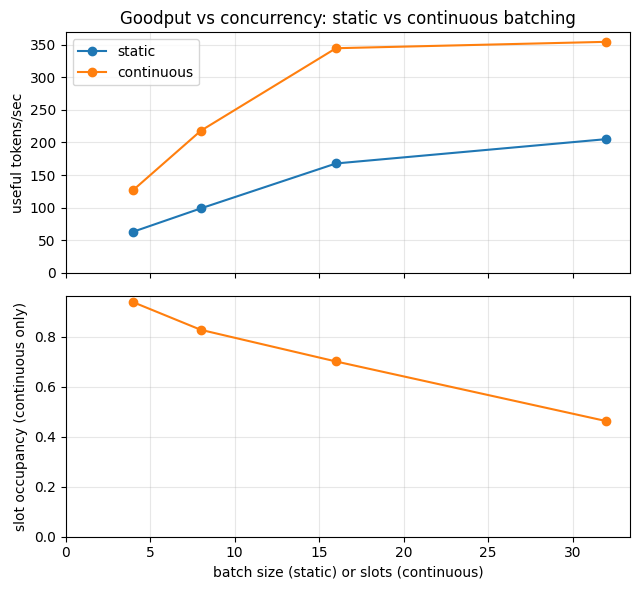

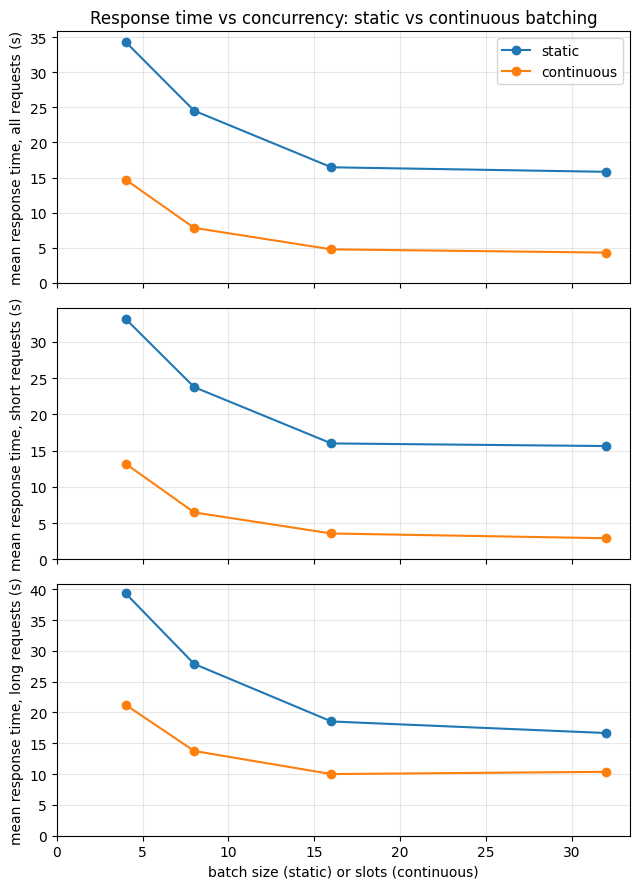

In [21]:
line_groups_stacked(closed_df, "B", ["goodput_tok_s", "slot_occupancy"], "policy",
                    "Goodput vs concurrency: static vs continuous batching",
                    ["useful tokens/sec", "slot occupancy (continuous only)"],
                    xlabel="batch size (static) or slots (continuous)", save="stage4_goodput_vs_slots")
line_groups_stacked(closed_df, "B", ["lat_mean_s", "short_lat_mean_s", "long_lat_mean_s"], "policy",
                    "Response time vs concurrency: static vs continuous batching",
                    ["mean response time, all requests (s)", "mean response time, short requests (s)",
                     "mean response time, long requests (s)"],
                    xlabel="batch size (static) or slots (continuous)", save="stage4_latency_vs_slots")

**How to read it.**

- **Goodput.** Continuous batching delivers about twice the goodput of static batching up to moderate concurrency, and somewhat less than twice at the largest pool (the `goodput_x` column of the ratio table). It never computes a finished request, while static batching's goodput stays far below its raw throughput (Stage 3). Continuous goodput stops rising, and even dips, once the slot count exceeds what this workload can keep full: the occupancy panel shows that a large pool is only partly occupied for a closed batch of this size.
- **Response time.** Mean response time falls by a factor of two to four (`mean_latency_x`). Short requests gain the most (`short_latency_x`): under static batching they are released with the longest request in their batch, under continuous batching when they are done, so the blocked time from Stage 3 is gone. Long requests gain less (`long_latency_x`), because they were never waiting for anyone.
- **Slot occupancy** (the bottom panel of the first figure and the last column of the table) falls as slots are added, and drops further near the end of the run, when the queue is empty and the last long requests are decoding alone.
- **The p99 is the makespan.** With 64 requests the p99 interpolates between the two slowest requests, which finish within a millisecond of each other, so it is essentially the slowest request and equals the run's total time. Read the p50 as the typical experience.
- Each point is a single run, so expect some noise.

---
## 5. B. Open-loop load: latency and throughput as the offered load rises

**Goal:** see how each policy behaves when requests arrive over time, which is how a server is actually used.

**Setup.** `N_LOAD` mixed requests arrive as a **Poisson process** at several rates (requests per second, the *offered load*). Both policies serve the **same** arrival trace at each rate, with the same concurrency limit `LOAD_B` (static batches of up to `LOAD_B`, or `LOAD_B` slots). Static batching takes whatever has arrived when the GPU is free, up to `LOAD_B`, and does not wait for a full batch. We record the time each request waits and the response time it sees.

**Concept.** At a low rate there is little to batch, so both policies serve one or two requests at a time and look alike. As the rate rises, static batching has to finish a whole batch, long requests included, before it can start the next one, so its queue grows long before the GPU is saturated. Continuous batching admits a request as soon as a slot is free. Past some offered load a server cannot keep up at all: the queue grows for as long as the run lasts, the response time climbs, and the completed throughput flattens below the offered load.

> **Predict:** at what offered load does each policy stop keeping up? Roughly how much higher is continuous batching's capacity?

In [22]:
N_LOAD, LOAD_B = (32 if QUICK else 64), 16
RATES = [1, 3, 6] if QUICK else [0.5, 1, 2, 3, 4, 6, 8]       # offered load, requests per second
load_reqs = make_requests(N_LOAD, seed=SEED, **WORKLOADS["mixed"])

load_rows = sweep_load(model, load_reqs, RATES, static_batch=LOAD_B, slots=LOAD_B, pad_id=PAD_ID, arrival_seed=1)
load_df = pd.DataFrame(load_rows)
load_df[["rate", "policy", "req_s", "goodput_tok_s", "utilization", "queue_mean_s", "lat_p50_s", "lat_p99_s",
         "ttft_p50_s", "ttft_p99_s", "blocked_mean_s"]].round(2)

rate  0.50/s  static     p50    4.3 s  p99   12.7 s  served 0.51/s
rate  0.50/s  continuous p50    1.0 s  p99    7.0 s  served 0.52/s
rate  1.00/s  static     p50    7.8 s  p99   13.2 s  served 0.95/s
rate  1.00/s  continuous p50    1.1 s  p99    7.6 s  served 0.99/s
rate  2.00/s  static     p50    8.8 s  p99   14.0 s  served 1.63/s
rate  2.00/s  continuous p50    1.1 s  p99    7.8 s  served 1.80/s
rate  3.00/s  static     p50   11.7 s  p99   17.4 s  served 1.93/s
rate  3.00/s  continuous p50    1.2 s  p99    7.9 s  served 2.48/s
rate  4.00/s  static     p50   14.0 s  p99   20.7 s  served 1.90/s
rate  4.00/s  continuous p50    1.1 s  p99    7.8 s  served 3.04/s
rate  6.00/s  static     p50   15.9 s  p99   24.8 s  served 1.89/s
rate  6.00/s  continuous p50    1.3 s  p99    8.4 s  served 3.91/s
rate  8.00/s  static     p50   13.9 s  p99   23.5 s  served 2.10/s
rate  8.00/s  continuous p50    1.4 s  p99    8.5 s  served 4.57/s


,rate,policy,req_s,goodput_tok_s,utilization,queue_mean_s,lat_p50_s,lat_p99_s,ttft_p50_s,ttft_p99_s,blocked_mean_s
0,0.5,static,0.51,34.19,0.69,1.66,4.26,12.65,0.88,6.17,1.17
1,0.5,continuous,0.52,34.89,0.60,0.01,1.01,6.98,0.03,0.07,0.00
2,1.0,static,0.95,63.62,0.93,2.37,7.79,13.25,1.98,6.73,2.95
3,1.0,continuous,0.99,66.47,0.83,0.01,1.10,7.60,0.04,0.08,0.00
4,2.0,static,1.63,109.08,1.00,3.04,8.83,14.00,2.82,8.23,3.17
5,2.0,continuous,1.80,120.73,0.98,0.02,1.14,7.76,0.04,0.08,0.00
6,3.0,static,1.93,129.07,1.00,5.24,11.73,17.44,5.21,10.87,4.54
7,3.0,continuous,2.48,165.99,1.00,0.02,1.16,7.95,0.04,0.09,0.00
8,4.0,static,1.90,127.10,1.00,6.99,14.04,20.67,7.22,14.09,4.60
9,4.0,continuous,3.04,203.54,1.00,0.02,1.13,7.78,0.04,0.07,0.00


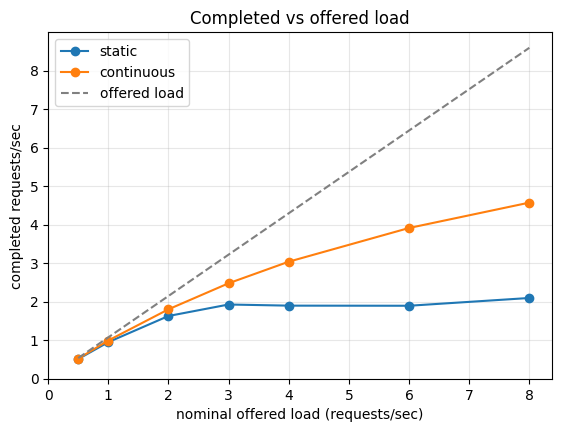

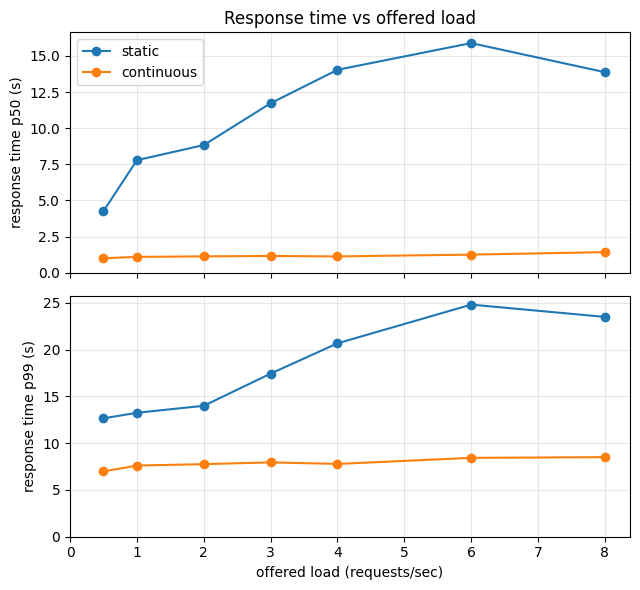

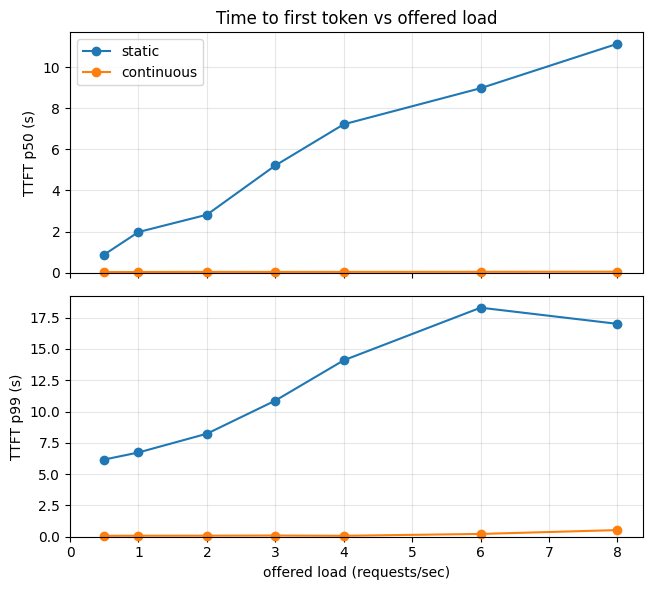

In [23]:
# the dashed line is the arrival rate the random trace actually realized, which scatters around the nominal rate
offered = (load_df[load_df.policy == "static"][["rate", "offered_req_s"]]
           .rename(columns={"offered_req_s": "req_s"}).assign(policy="offered load"))
line_groups(pd.concat([load_df[["rate", "req_s", "policy"]], offered]), "rate", "req_s", "policy",
            "Completed vs offered load", "completed requests/sec", xlabel="nominal offered load (requests/sec)",
            save="stage4_throughput_vs_load")
line_groups_stacked(load_df, "rate", ["lat_p50_s", "lat_p99_s"], "policy", "Response time vs offered load",
                    ["response time p50 (s)", "response time p99 (s)"], xlabel="offered load (requests/sec)",
                    save="stage4_latency_vs_load")
line_groups_stacked(load_df, "rate", ["ttft_p50_s", "ttft_p99_s"], "policy", "Time to first token vs offered load",
                    ["TTFT p50 (s)", "TTFT p99 (s)"], xlabel="offered load (requests/sec)", save="stage4_ttft_vs_load")

**How to read it.**

- **Static batching queues at the lowest load.** A request that arrives while a batch is running must wait for the whole batch, long requests included, so its time to first token is already far above continuous batching's at light load, and both its response time and its time to first token climb with every step in the offered load. Its completed rate flattens at a low level well below the offered load: that is its capacity.
- **Continuous batching barely queues.** It admits a request as soon as a slot is free, so its median response time and time to first token stay nearly flat across the sweep, and it only starts to queue at the top of the range. Its completed rate keeps rising to more than twice the level where static batching flattens, and it has not flattened yet, so its capacity is at least that high.
- **Read saturation from the queue, not from the completed rate or the GPU.** The completed-versus-offered plot understates continuous batching's capacity: a finite trace ends only when the last long request has drained, so the completed rate bends away from the offered load even before a queue forms. And "GPU busy" stays near 100% while slots are still free, because a decode step costs about the same for a few or many live requests (Stage 3). What saturates a continuous server is its slot count. Use the time to first token and the queueing time.
- The p99 over a few dozen requests is simply the slowest request, so read the p50 as the typical experience. The arrival trace is one random sample per rate, so expect some noise, especially in the tail.

---
## 6. C. Prefill interference: what a new request costs the others

**Goal:** measure the cost continuous batching introduces.

**Concept.** A new request must be prefilled before it can decode, and that prefill runs *between* decode steps: while it runs, every request already in a slot waits. So the gap a running request sees between two tokens is a decode step **plus** any prefills that ran in between. `max_prefills` limits how many prefills may run per iteration. A small budget protects the running requests (their gaps stay short) but makes new requests wait for a share of the budget (their time to first token grows), and a large budget does the opposite. Real servers chunk long prompts for the same reason (exercise 1).

**Setup.** One moderately loaded arrival trace (`RATE_C` requests per second, the same requests as section 5), served by `LOAD_B` slots with different prefill budgets.

> **Predict:** with a budget of one prefill per iteration, does the p99 gap between tokens fall or rise? What happens to the TTFT?

In [24]:
RATE_C = 4.0
BUDGETS = [1, 2, 4, None]            # prefills allowed per iteration (None = fill every free slot)
trace = with_arrivals(load_reqs, RATE_C, seed=1)

rows, runs_c = [], {}
for budget in BUDGETS:
    run = run_continuous(model, trace, LOAD_B, PAD_ID, max_prefills=budget)
    runs_c[budget] = run
    s = summarize_online(run)
    rows.append({"max_prefills": "all" if budget is None else str(budget), **s})
budget_df = pd.DataFrame(rows)
budget_df[["max_prefills", "ttft_p50_s", "ttft_p99_s", "itl_p50_ms", "gap_p50_ms", "gap_p99_ms", "gap_max_ms",
           "prefill_share", "lat_p50_s", "goodput_tok_s"]].round(2)

,max_prefills,ttft_p50_s,ttft_p99_s,itl_p50_ms,gap_p50_ms,gap_p99_ms,gap_max_ms,prefill_share,lat_p50_s,goodput_tok_s
0,1,0.04,0.15,28.41,28.52,58.16,68.31,0.08,1.20,204.17
1,2,0.04,0.10,28.33,28.49,58.89,80.98,0.08,1.20,204.16
2,4,0.04,0.09,27.93,28.02,56.62,106.71,0.08,1.18,206.39
3,all,0.04,0.09,28.46,28.63,57.88,86.92,0.08,1.19,203.61


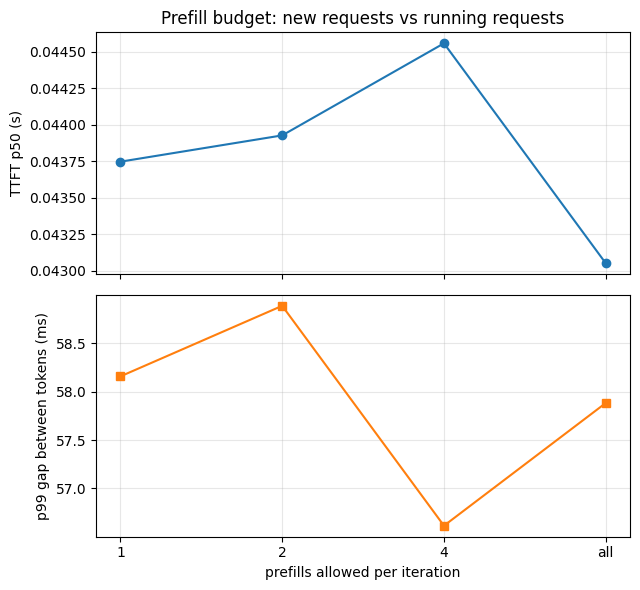

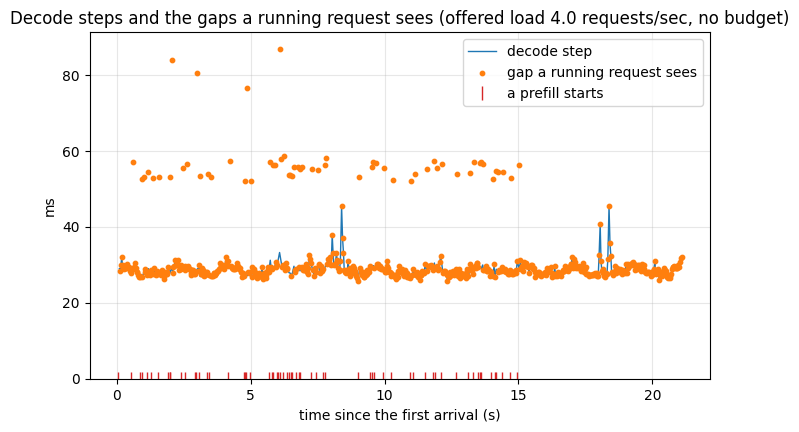

In [25]:
line_stacked(budget_df, "max_prefills", "ttft_p50_s", "gap_p99_ms",
             "Prefill budget: new requests vs running requests", "TTFT p50 (s)", "p99 gap between tokens (ms)",
             xlabel="prefills allowed per iteration", save="stage4_prefill_budget", zero=False)
step_timeline(runs_c[None].steps, runs_c[None].prefills,
              f"Decode steps and the gaps a running request sees (offered load {RATE_C} requests/sec, no budget)",
              save="stage4_step_timeline")

**How to read it.**

- **The gap is longer than the step.** The median gap a running request sees between two tokens is just the decode step, but the tail gap is about twice that: a decode step plus one prefill. The timeline shows it directly: the orange dots sit on the decode-step line except where a prefill (red tick) pushed them up.
- **The budget moves the worst gap, not the typical one.** A limit of one prefill per iteration clearly shortens the single worst gap, but the p99 gap does not fall: it is about the same, even slightly higher. A budget spreads the same prefills over more iterations, so more decode steps are slowed by one prefill each, instead of a few steps being slowed by several prefills at once. The price is a longer tail of first-token time, while the median does not move. At this load the effect is small: a prefill is cheap in this launch-bound regime (about one decode step, a small share of the GPU time) and rarely is more than one request waiting. The cost grows with longer prompts and heavier load, which is why production servers split long prompts into chunks (exercise 1).
- Decode steps themselves stay flat, as in Stage 3. This is one arrival trace per budget, so expect some noise in the tail.

---
## 7. D. KV slot reservation: what is still wasted

**Goal:** count how much of the slot pool actually holds tokens.

**Concept.** Continuous batching fixed the *compute* waste, but each slot is still a rectangle of `max_len` tokens, sized for the longest request the workload can produce, whatever the request in it needs. A request that needs a short prompt and a short answer holds the same reservation as the longest one, and a request that has just started holds almost none of it in use. `kv_slot_util` is the KV tokens in use divided by the token capacity of the whole pool, averaged over the decode steps. This section reuses the continuous runs from section 4, so it takes no extra time.

The last two columns are upper bounds on what *paged* allocation could gain at the same memory: how many times more sequences would fit if the memory followed the average use, or the peak use, instead of the worst case. Stage 5 builds that.

> **Predict:** with `B` slots, what fraction of the pool holds tokens on average? Does it get better or worse as `B` grows?

In [26]:
cont = closed_df[closed_df["policy"] == "continuous"]
kv_df = pd.DataFrame({
    "slots": cont["B"].to_numpy(),
    "slot_max_len": cont["slot_max_len"].to_numpy(),
    "kv_slot_util_pct": 100 * cont["kv_slot_util"].to_numpy(),
    "pool_mib": cont["B"].to_numpy() * cont["slot_max_len"].to_numpy() * bpt / 2**20,
    "peak_in_use_mib": cont["kv_peak_tokens"].to_numpy() * bpt / 2**20,
})
# capacity multiple if memory followed use instead of the worst case: pool tokens / tokens in use
kv_df["paged_gain_avg_x"] = 100 / kv_df["kv_slot_util_pct"]
kv_df["paged_gain_peak_x"] = kv_df["slots"] * kv_df["slot_max_len"] / cont["kv_peak_tokens"].to_numpy()
kv_df.round(1)

,slots,slot_max_len,kv_slot_util_pct,pool_mib,peak_in_use_mib,paged_gain_avg_x,paged_gain_peak_x
0,4,732.0,31.7,34.3,19.9,3.2,1.7
1,8,732.0,28.0,68.6,34.8,3.6,2.0
2,16,732.0,23.7,137.2,56.1,4.2,2.4
3,32,732.0,15.6,274.5,81.4,6.4,3.4


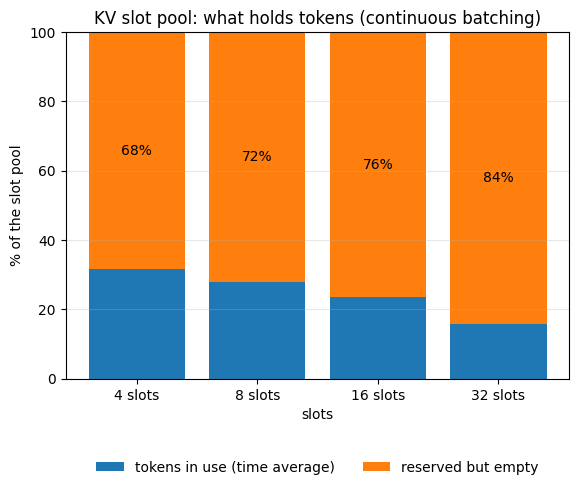

In [27]:
stacked_bar([f"{b} slots" for b in kv_df["slots"]],
            {"tokens in use (time average)": list(kv_df["kv_slot_util_pct"]),
             "reserved but empty": list(100 - kv_df["kv_slot_util_pct"])},
            "KV slot pool: what holds tokens (continuous batching)", "% of the slot pool",
            xlabel="slots", annotate=True, ylim=(0, 100), save="stage4_kv_slots")

**How to read it.**

- **Most of the pool is empty on average.** Two things cause it: every slot is sized for the *longest* possible request, and a running sequence is on average only part-way through its generation. Unlike Stage 3's static rectangle, the waste is not padding and finished tails but **reservation**: memory held for tokens that may never exist.
- **The share falls as slots are added.** The reservation is per slot, so absolute reserved memory grows in proportion to the slot count, while a larger pool is less often full, so a smaller share of it holds tokens.
- **Paged allocation would fit a few times more sequences** in the same memory (the last two columns), which lets a server raise the slot count, and so the throughput, until compute rather than memory is the limit. These are *upper bounds*: the average undercounts the memory needed at the busiest moment, so the peak-based column is the more honest one.
- For this small model, memory does not bind (its cache is tiny next to a 15 GiB GPU). For a model with a large KV footprint per token (Stage 3's projection), the reservation caps the slot count at a handful.

---
## 8. Save results

`results/stage4.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revision, and every experiment parameter,
- `closed`: section 4 (static vs continuous at each concurrency),
- `load`: section 5 (both policies at each offered load),
- `prefill_budget` and `timeline`: section 6 (the budget sweep, and the decode steps and prefills of one run),
- `kv_slots`: section 7.

Final published numbers should come from one consistent environment.

In [28]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(4).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

tl = runs_c[None]
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "workload": "mixed", "workloads": WORKLOADS,
        "closed": {"n_requests": N_CLOSED, "concurrency": CLOSED_B},
        "load": {"n_requests": N_LOAD, "concurrency": LOAD_B, "rates": RATES, "arrival_seed": 1},
        "prefill_budget": {"rate": RATE_C, "budgets": ["all" if b is None else b for b in BUDGETS], "slots": LOAD_B},
        "short_max_new": 48,
    },
    "closed": records(closed_df),
    "load": records(load_df),
    "prefill_budget": records(budget_df),
    "timeline": {
        "steps": {"start_s": [round(s["start_s"], 4) for s in tl.steps], "step_s": [round(s["step_s"], 5) for s in tl.steps],
                  "gap_s": [None if s["gap_s"] is None else round(s["gap_s"], 5) for s in tl.steps],
                  "active": [s["active"] for s in tl.steps]},
        "prefills": {"start_s": [round(p["start_s"], 4) for p in tl.prefills], "prefill_s": [round(p["prefill_s"], 5) for p in tl.prefills],
                     "prompt_len": [p["prompt_len"] for p in tl.prefills]},
    },
    "kv_slots": records(kv_df),
}
save_results("results/stage4.json", out)

saved results/stage4.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [29]:
FIGURES = {
    "stage4_goodput_vs_slots.png": "Goodput and slot occupancy vs concurrency, static vs continuous batching (section 4)",
    "stage4_latency_vs_slots.png": "Mean response time of all, short and long requests vs concurrency, static vs continuous (section 4)",
    "stage4_throughput_vs_load.png": "Completed vs offered load, static vs continuous (section 5)",
    "stage4_latency_vs_load.png": "Response time p50 and p99 vs offered load, static vs continuous (section 5)",
    "stage4_ttft_vs_load.png": "Time to first token p50 and p99 vs offered load, static vs continuous (section 5)",
    "stage4_prefill_budget.png": "TTFT and the p99 gap between tokens vs the prefill budget (section 6)",
    "stage4_step_timeline.png": "Decode steps, the gaps a running request sees and the prefills between them (section 6)",
    "stage4_kv_slots.png": "What holds tokens in the KV slot pool, by slot count (section 7)",
}
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage4_goodput_vs_slots.png,"Goodput and slot occupancy vs concurrency, sta..."
1,stage4_latency_vs_slots.png,"Mean response time of all, short and long requ..."
2,stage4_throughput_vs_load.png,"Completed vs offered load, static vs continuou..."
3,stage4_latency_vs_load.png,"Response time p50 and p99 vs offered load, sta..."
4,stage4_ttft_vs_load.png,Time to first token p50 and p99 vs offered loa...
5,stage4_prefill_budget.png,TTFT and the p99 gap between tokens vs the pre...
6,stage4_step_timeline.png,"Decode steps, the gaps a running request sees ..."
7,stage4_kv_slots.png,"What holds tokens in the KV slot pool, by slot..."


---
## 9. Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [30]:
PUSH = True                                   # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 4: continuous batching"   # the only other line that differs between notebooks
FORCE_CODE = False                            # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 665, done.        
remote: Counting objects: 100% (52/52), done.        
remote: Compressing objects: 100% (45/45), done.        
remote: Total 665 (delta 16), reused 31 (delta 6), pack-reused 613 (from 1)        
Receiving objects: 100% (665/665), 15.12 MiB | 26.83 MiB/s, done.
Resolving deltas: 100% (314/314), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 4, repo code stage 4: publishing code and results
[main dd4267d] Stage 4: continuous batching
 8 files changed, 2826 insertions(+), 3130 deletions(-)
Enumerating objects: 19, done.
Counting objects: 100% (19/19), done.
Delta compression using up to 4 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (11/11), 489.97 KiB | 14.00 MiB/s, done.
Total 11 (delta 2), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.git
   d9ccc56..dd4267d  HEAD -> main


---
## 10. Summary

In [31]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

top = max(CLOSED_B)
cs = closed_df[(closed_df.B == 16 if 16 in CLOSED_B else closed_df.B == top)]
st, ct = cs[cs.policy == "static"].iloc[0], cs[cs.policy == "continuous"].iloc[0]
hi = load_df[load_df.rate == load_df.rate.max()]
hs, hc = hi[hi.policy == "static"].iloc[0], hi[hi.policy == "continuous"].iloc[0]
lo = load_df[load_df.rate == load_df.rate.min()]
ls, lc = lo[lo.policy == "static"].iloc[0], lo[lo.policy == "continuous"].iloc[0]
b_all, b_one = budget_df[budget_df.max_prefills == "all"].iloc[0], budget_df[budget_df.max_prefills == "1"].iloc[0]
kvb = kv_df.iloc[-1]

show_table([
    (f"Goodput at B={int(st.B)}",
     f"static {st.goodput_tok_s:.0f} -> continuous {ct.goodput_tok_s:.0f} tok/s",
     f"{ct.goodput_tok_s / st.goodput_tok_s:.1f}x, same requests, same concurrency"),
    (f"Short-request response time at B={int(st.B)}",
     f"static {st.short_lat_mean_s:.1f} s -> continuous {ct.short_lat_mean_s:.1f} s",
     f"static blocked time {st.blocked_mean_s:.1f} s per request, continuous {ct.blocked_mean_s:.1f} s"),
    (f"Latency p50 at {lo.rate.iloc[0]} req/s",
     f"static {ls.lat_p50_s:.1f} s, continuous {lc.lat_p50_s:.1f} s",
     "static already queues at light load"),
    (f"Latency p50 at {hi.rate.iloc[0]} req/s",
     f"static {hs.lat_p50_s:.1f} s, continuous {hc.lat_p50_s:.1f} s",
     f"completed {hs.req_s:.1f} vs {hc.req_s:.1f} req/s, offered {hs.offered_req_s:.1f}"),
    (f"TTFT p50 at {hi.rate.iloc[0]} req/s",
     f"static {hs.ttft_p50_s:.1f} s, continuous {hc.ttft_p50_s:.2f} s", "queueing for a batch vs for a slot"),
    ("Prefill budget",
     f"worst gap {b_one.gap_max_ms:.0f} ms (one prefill per step) vs {b_all.gap_max_ms:.0f} ms (no limit)",
     f"p99 gap {b_one.gap_p99_ms:.0f} vs {b_all.gap_p99_ms:.0f} ms", 
     f"TTFT p99 {b_one.ttft_p99_s:.2f} vs {b_all.ttft_p99_s:.2f} s; decode step p50 {b_all.itl_p50_ms:.0f} ms"),
    (f"KV slot pool ({int(kvb.slots)} slots)",
     f"{kvb.kv_slot_util_pct:.0f}% of the pool holds tokens on average",
     f"{kvb.paged_gain_peak_x:.1f}x more sequences would fit at peak use if allocation followed use"),
])

| Metric | Result | Note |
|---|---|---|
| **Goodput at B=16** | static 168 -> continuous 345 tok/s | 2.1x, same requests, same concurrency |
| **Short-request response time at B=16** | static 16.0 s -> continuous 3.6 s | static blocked time 4.1 s per request, continuous 0.0 s |
| **Latency p50 at 0.5 req/s** | static 4.3 s, continuous 1.0 s | static already queues at light load |
| **Latency p50 at 8.0 req/s** | static 13.9 s, continuous 1.4 s | completed 2.1 vs 4.6 req/s, offered 8.6 |
| **TTFT p50 at 8.0 req/s** | static 11.1 s, continuous 0.05 s | queueing for a batch vs for a slot |
| **Prefill budget** | worst gap 68 ms (one prefill per step) vs 87 ms (no limit) | p99 gap 58 vs 58 ms | TTFT p99 0.15 vs 0.09 s; decode step p50 28 ms |
| **KV slot pool (32 slots)** | 16% of the pool holds tokens on average | 3.4x more sequences would fit at peak use if allocation followed use |

### What we learned

#### Questions

- **Does continuous batching win back what Stage 3 lost?** (Section 4: goodput and short-request response time at the same concurrency.)
- **Where does it matter most?** (Section 5: light load vs heavy load, and the capacity of each policy.)
- **What does it cost?** (Section 6: the prefills that interrupt running requests.)
- **What is left?** (Section 7: the reservation per slot, and the capacity it caps.)

#### Answers

- **Yes, it wins back what Stage 3 lost.** At the same concurrency and with the same requests, continuous batching delivers roughly twice the goodput, and mean response time falls by a factor of two to four. Short requests gain the most, because they leave when they are done instead of when the longest request in their batch is.
- **It matters most under load.** Static batching queues even at light load, because a new request waits for a whole batch, and its capacity is low. Continuous batching admits at once, so its response and first-token times stay flat until the slots run out, and its capacity is more than twice as high. Judge saturation from the queue and the time to first token, not from GPU utilization or from the completed rate of a short trace.
- **It costs one prefill per new request.** A prefill runs between decode steps, so the tail gap between tokens is a decode step plus a prefill. A prefill budget shortens the worst gap at some cost in tail first-token latency, but it barely moves the p99 gap, and the effect is small here because prefills are cheap.
- **What is left is the reservation.** Each slot holds a worst-case rectangle, so only a minority of the pool holds tokens, and a paged cache would fit a few times more sequences in the same memory. That is Stage 5.

### Next: Stage 5, paged KV cache

Continuous batching keeps the batch full, so the next bottleneck is **memory**: every slot reserves a worst-case rectangle, so the number of sequences that fit, and with it the throughput, is capped by memory long before the GPU is busy. A **paged** cache allocates the KV in small fixed-size blocks from a shared pool, through a per-sequence block table, so a sequence holds only the blocks it has filled, and finished sequences return theirs at once. That needs a block allocator, a block table that the attention gathers through, and an experiment that compares fragmentation and capacity before and after.

### Exercises

1. **Chunk the prompts.** Prefill a long prompt in chunks of 128 tokens across several iterations instead of all at once. What happens to the p99 gap between tokens, and to the TTFT of that request?
2. **A longer-running mix.** Increase `N_LOAD` and the arrival rate. Does the gap between the two policies' capacity grow? When does the closed-batch tail effect of section 4 stop mattering?
3. **Prefill priority.** Admit waiting requests shortest-prompt-first instead of first-come-first-served. What does it do to the median and to the tail of the TTFT?
4. **Chunked prefill and the budget.** Combine a prefill budget with chunking. Which of the two moves the p99 gap more?
5. **Slot count.** Sweep the slot count at a fixed offered load. Where does adding slots stop helping, and what does it cost in reserved KV?

### References

- Yu et al., *Orca: A Distributed Serving System for Transformer-Based Generative Models* (OSDI 2022), the origin of iteration-level (continuous) scheduling: https://www.usenix.org/conference/osdi22/presentation/yu
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180
- Agrawal et al., *Taming Throughput-Latency Tradeoff in LLM Inference with Sarathi-Serve* (chunked prefill): https://arxiv.org/abs/2403.02310

---

# Appendix

Refer to the simple examples below to understand how `SlotCache` and the continuous scheduler work.

## A.1. A slot cache (`SlotCache`)

In [32]:
import torch
from minivllm.kv_cache import SlotCache

c = SlotCache(n_layers=1, slots=3, n_kv_heads=1, max_len=8, head_dim=2, device="cpu", dtype=torch.float32)
k = lambda T: torch.randn(1, 1, T, 2)

view = c.prefill_view(0); view.update(0, k(5), k(5)); view.advance(5)     # a 5-token prompt into slot 0
view = c.prefill_view(2); view.update(0, k(3), k(3)); view.advance(3)     # a 3-token prompt into slot 2
print("lens:", c.lens, "(slot 1 is free)")

dv = c.decode_view()                                                       # one new token for EVERY slot
print("columns each slot writes next:", dv.cols.tolist(), "| columns that can matter this step:", dv.end)
mask = (torch.arange(dv.end)[None, :] <= torch.tensor(c.lens)[:, None])
print("who may attend to which column (rows = slots, True = may attend):")
print(mask.int())

c.free(0)
print("\nafter freeing slot 0:", c.lens, "-> the slot is reusable at once; its old keys are masked, not erased")

lens: [5, 0, 3] (slot 1 is free)
columns each slot writes next: [5, 0, 3] | columns that can matter this step: 6
who may attend to which column (rows = slots, True = may attend):
tensor([[1, 1, 1, 1, 1, 1],
        [1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0]], dtype=torch.int32)

after freeing slot 0: [0, 0, 3] -> the slot is reusable at once; its old keys are masked, not erased


## A.2. Five toy requests, three schedulers

The same five requests go through `run_static`, `run_static_online` and `run_continuous`, with at most **two** running at a time, so the scheduler is the only thing that changes. Request 1 has a long answer, the others are short. Requests 2 and 3 arrive while the first two are still running, and request 4 arrives when everything is idle. The helper below draws a timeline with one row per request.

In [33]:
toy = [Request(0, tok("The capital of France is").input_ids, 4, arrival_s=0.00),
       Request(1, tok("Once upon a time there was").input_ids, 12, arrival_s=0.00),
       Request(2, tok("2 + 2 =").input_ids, 3, arrival_s=0.05),
       Request(3, tok("def add(a, b):").input_ids, 6, arrival_s=0.10),
       Request(4, tok("Hello").input_ids, 2, arrival_s=0.40)]

def gantt(results, dt=0.02, title=""):
    """One row per request, one character per `dt` seconds."""
    end = max(r.release_s for r in results)
    n = int(round(end / dt)) + 1
    print(f"{title}   (one character = {int(dt*1000)} ms, total {end:.2f} s)")
    for r in sorted(results, key=lambda r: r.id):
        row = ""
        for i in range(n):
            t = i * dt
            row += (" " if t < r.arrival_s else "." if t < r.admit_s else "P" if t < r.first_token_s else
                    "#" if t < r.finish_s else "x" if t < r.release_s else " ")
        print(f"  request {r.id} |{row}|")
    print("  . waiting   P prefill   # decoding   x finished but not yet returned (static only)\n")

pd.DataFrame([{"id": r.id, "arrival": r.arrival_s, "prompt tokens": len(r.prompt_ids), "new tokens": r.max_new} for r in toy])

,id,arrival,prompt tokens,new tokens
0,0,0.00,5,4
1,1,0.00,6,12
2,2,0.05,5,3
3,3,0.10,6,6
4,4,0.40,1,2


## A.3. `run_static`: everything arrives at t = 0, waves run back to back

`run_static` is the Stage 3 scheduler: it ignores arrival times and runs the requests in waves of two. A wave is released when its **longest** request ends, so a short request that finished early is held back. `blocked` = `release` minus `finish`, the quantity Section 4 averaged.

In [34]:
# A.3 run_static: everything arrives at 0 and waves run back to back (batch of 2)
toy_run_st0 = run_static(model, [Request(r.id, r.prompt_ids, r.max_new) for r in toy], batch_size=2, pad_id=PAD_ID)
pd.DataFrame([{"id": r.id, "wave": r.wave, "first token": r.first_token_s, "finish": r.finish_s,
               "release": r.release_s, "blocked": r.release_s - r.finish_s} for r in toy_run_st0.results]).round(3)

,id,wave,first token,finish,release,blocked
0,0,0,0.030,0.108,0.326,0.218
1,1,0,0.030,0.326,0.326,0.000
2,2,1,0.355,0.411,0.496,0.085
3,3,1,0.355,0.496,0.496,0.000
4,4,2,0.526,0.557,0.557,0.000


## A.4. `run_static_online`: the same requests, now with arrivals

Whenever the GPU is free it takes the requests that have already arrived (up to two) and runs them as one wave. It never waits for a full batch. In the timeline, look for `x`: a short request that finished but is still waiting for its wave to return, and for the long `.` runs of later requests waiting for the whole current wave.

In [35]:
# A.4 run_static_online: same requests with arrivals; a wave takes what has arrived, never waits for more
toy_run_so = run_static_online(model, toy, batch_size=2, pad_id=PAD_ID)
gantt(toy_run_so.results, title="static, online")

static, online   (one character = 20 ms, total 0.57 s)
  request 0 |PP####xxxxxxxxxxxx           |
  request 1 |PP################           |
  request 2 |   ...............P###xxxx   |
  request 3 |     .............P#######   |
  request 4 |                    ......PP#|
  . waiting   P prefill   # decoding   x finished but not yet returned (static only)



## A.5. `run_continuous`: same requests, same two slots

Each request is prefilled into a free slot as soon as there is one, and released the moment it is done, so there is no `x` and a waiting request takes over a slot at once. Prefills run one after another, which is why request 1 waits briefly behind request 0's prefill. The table gives the exact times, and the last line shows how many requests ran in each decode step.

In [36]:
toy_run_co = run_continuous(model, toy, slots=2, pad_id=PAD_ID)
pd.DataFrame([{"id": r.id, "arrival": r.arrival_s, "admit": r.admit_s, "first token": r.first_token_s,
               "finish = release": r.finish_s, "new tokens": r.max_new} for r in toy_run_co.results]).round(3)

,id,arrival,admit,first token,finish = release,new tokens
0,0,0.00,0.000,0.030,0.135,4
1,1,0.00,0.030,0.054,0.407,12
2,2,0.05,0.135,0.160,0.215,3
3,3,0.10,0.215,0.241,0.379,6
4,4,0.40,0.407,0.431,0.459,2


In [37]:
print("running requests per decode step:", [s["active"] for s in toy_run_co.steps])
print("prefills (id, started at):", [(p["id"], round(p["start_s"], 3)) for p in toy_run_co.prefills])

running requests per decode step: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1]
prefills (id, started at): [(0, 0.0), (1, 0.03), (2, 0.135), (3, 0.215), (4, 0.407)]


In [38]:
# A.5 run_continuous: same requests, same 2 slots
gantt(toy_run_co.results, title="continuous")

continuous   (one character = 20 ms, total 0.46 s)
  request 0 |PP#####                 |
  request 1 |..P##################   |
  request 2 |   ....PP##             |
  request 3 |     ......PP######     |
  request 4 |                    .P# |
  . waiting   P prefill   # decoding   x finished but not yet returned (static only)



Compare the two timelines: the same requests finish much earlier under continuous batching, because nothing waits for a stranger's long answer and no slot sits idle while someone is queued.